# 1. Import Libraries 

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt 
# set default grayscale to show image by plt
plt.rc('image', cmap='gray')
plt.rc('figure', autolayout=True)

I0000 00:00:1779374217.449966   12168 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1779374217.518927   12168 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1779374242.243103   12168 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [ ]:
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# 2.Load and preprocess the image 

In [ ]:
image_path = "../data/images/image1.png"
image = tf.io.read_file(image_path)
image.shape

I0000 00:00:1779374261.055643   12168 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1765 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


TensorShape([])

In [ ]:
# Đọc file ảnh từ dạng byte thô -> tensor số 
image = tf.io.decode_jpeg(image, channels=1) 
# Resize ảnh về kích thước 300x300  
image = tf.image.resize(image, [900, 900])
# Chuyển pixel 0-255 về khoảng 0.0 - 1.0 
image = tf.image.convert_image_dtype(image, tf.float32)
image = image/255
print("Original Image Shape:", image.shape)

Original Image Shape: (900, 900, 1)


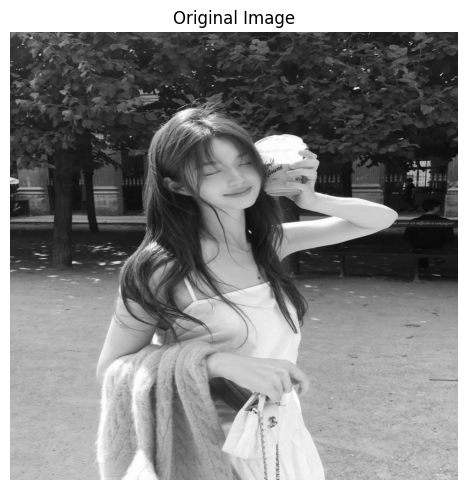

In [ ]:
plt.figure(figsize=(5,5))
plt.imshow(tf.squeeze(image))
plt.title("Original Image")
plt.axis('off')
plt.show()

image = tf.expand_dims(image, axis=0)

# 3. Define Convolution Kernel 

In [ ]:
kernel = tf.constant([
    [-1,0,-1], 
    [-1,8,-1],
    [-1,-1,-1]
], dtype=tf.float32)

In [ ]:
kernel

<tf.Tensor: shape=(3, 3), dtype=float32, numpy=
array([[-1.,  0., -1.],
       [-1.,  8., -1.],
       [-1., -1., -1.]], dtype=float32)>

In [ ]:
kernel=tf.reshape(kernel, [3,3,1,1])
kernel

<tf.Tensor: shape=(3, 3, 1, 1), dtype=float32, numpy=
array([[[[-1.]],

        [[ 0.]],

        [[-1.]]],


       [[[-1.]],

        [[ 8.]],

        [[-1.]]],


       [[[-1.]],

        [[-1.]],

        [[-1.]]]], dtype=float32)>

# 4. Apply Convolution Layer

In [ ]:

conv_output = tf.nn.conv2d(
    input=image, 
    filters=kernel,
    strides=[1,1,1,1], 
    padding='SAME'
)
print('After Convolution Shape: ', conv_output.shape)

I0000 00:00:1779374262.161632   12168 cuda_dnn.cc:461] Loaded cuDNN version 92101


After Convolution Shape:  (1, 900, 900, 1)


## 📊 Stride Explanation

| Vị trí      | Giá trị | Tại sao luôn = 1?                                   |
| ----------- | ------- | --------------------------------------------------- |
| [0] batch   | 1       | Bắt buộc = 1, không được bỏ qua ảnh nào trong batch |
| [1] height  | 1       | Trượt 1 pixel theo chiều dọc                        |
| [2] width   | 1       | Trượt 1 pixel theo chiều ngang                      |
| [3] channel | 1       | Bắt buộc = 1, không được bỏ qua kênh nào            |


In [ ]:
conv_output

<tf.Tensor: shape=(1, 900, 900, 1), dtype=float32, numpy=
array([[[[2.1677246 ],
         [1.1828613 ],
         [1.1083984 ],
         ...,
         [0.6329346 ],
         [0.68933105],
         [1.1380615 ]],

        [[1.9501953 ],
         [0.36279297],
         [0.28271484],
         ...,
         [0.20593262],
         [0.2593994 ],
         [0.9458008 ]],

        [[1.9436035 ],
         [0.24560547],
         [0.24072266],
         ...,
         [0.15808105],
         [0.2130127 ],
         [0.89367676]],

        ...,

        [[2.864746  ],
         [0.75      ],
         [0.7988281 ],
         ...,
         [0.7163086 ],
         [0.7685547 ],
         [2.9746094 ]],

        [[3.1230469 ],
         [0.8676758 ],
         [0.89501953],
         ...,
         [0.6982422 ],
         [0.5078125 ],
         [2.4482422 ]],

        [[4.645508  ],
         [3.005371  ],
         [3.0253906 ],
         ...,
         [2.7675781 ],
         [2.659668  ],
         [4.2773438 ]]]], sha

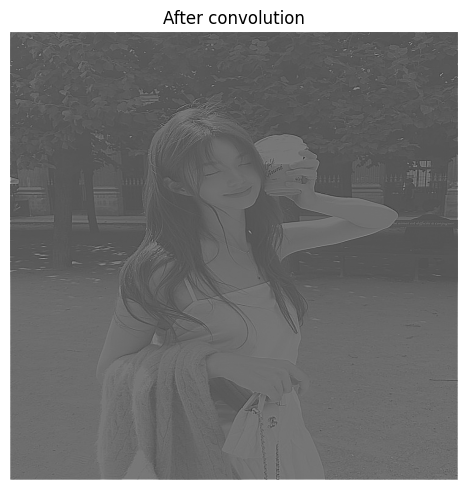

In [ ]:
plt.figure(figsize=(5,5))
plt.imshow(tf.squeeze(conv_output))
plt.title("After convolution")
plt.axis('off')
plt.show()

In [ ]:
conv_output1 = tf.nn.conv2d(
    input=image, 
    filters=kernel,
    strides=[1,2,2,1], 
    padding='SAME'
)
print('After Convolution Shape: ', conv_output1.shape)

After Convolution Shape:  (1, 450, 450, 1)


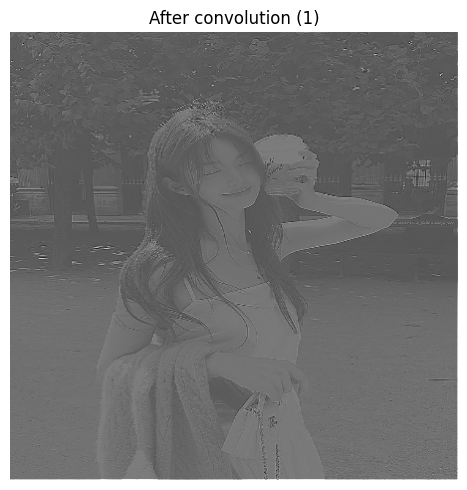

In [ ]:
plt.figure(figsize=(5,5))
plt.imshow(tf.squeeze(conv_output1))
plt.title("After convolution (1)")
plt.axis('off')
plt.show()

# 5. Apply ReLU Activation Function

After ReLU Shape:  (1, 900, 900, 1)


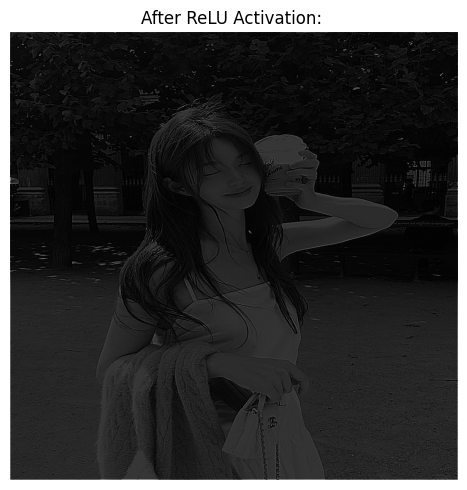

In [ ]:
relu_output = tf.nn.relu(conv_output)
print("After ReLU Shape: ", relu_output.shape)
plt.figure(figsize=(5,5))
plt.imshow(tf.squeeze(relu_output))
plt.title("After ReLU Activation: ")
plt.axis('off')
plt.show()

After ReLU Shape:  (1, 450, 450, 1)


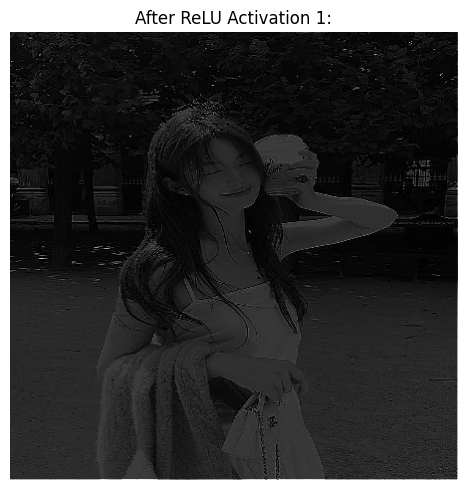

In [ ]:
relu_output1 = tf.nn.relu(conv_output1)
print("After ReLU Shape: ", relu_output1.shape)
plt.figure(figsize=(5,5))
plt.imshow(tf.squeeze(relu_output1))
plt.title("After ReLU Activation 1:")
plt.axis('off')
plt.show()

# 6. Apply Max pooling layer 

In [ ]:
pool_output = tf.nn.max_pool2d(
    input=relu_output, 
    ksize=[1,2,2,1],
    strides=[1,2,2,1],
    padding='SAME'
)
print("After pooling Shape:", pool_output.shape)

After pooling Shape: (1, 450, 450, 1)


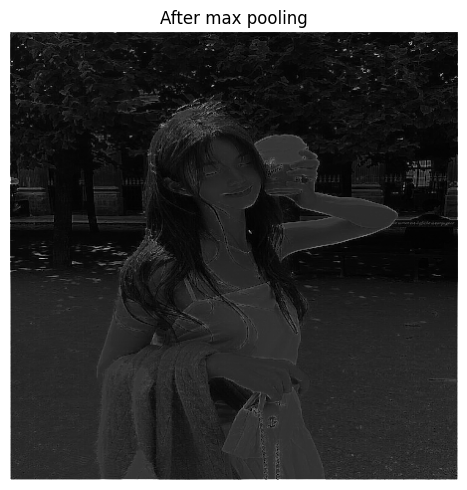

In [ ]:
plt.figure(figsize=(5,5))
plt.imshow(tf.squeeze(pool_output))
plt.title("After max pooling")
plt.axis('off')
plt.show()

In [ ]:
pool_output1 = tf.nn.max_pool2d(
    input=relu_output1,
    ksize=[1,2,2,1],
    strides=[1,2,2,1],
    padding='SAME'
)

print("After pooling shape", pool_output1.shape)

After pooling shape (1, 225, 225, 1)


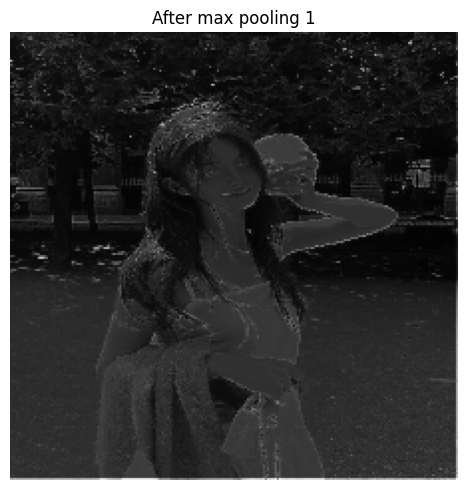

In [ ]:
plt.figure(figsize=(5,5))
plt.imshow(tf.squeeze(pool_output1))
plt.title("After max pooling 1")
plt.axis('off')
plt.show()

# 7. Apply Flatten Layer

In [ ]:
flatten_layer = tf.keras.layers.Flatten() 
flatten_output = flatten_layer(pool_output)

print("After Flatten Shape: ", flatten_output.shape)
print("First 20 flattened Values: ")
print(flatten_output.numpy()[0][:20])

After Flatten Shape:  (1, 202500)
First 20 flattened Values: 
[2.1677246 1.1298828 1.6713867 1.5371094 1.6218262 1.4929199 1.4655762
 1.375     1.1950684 1.3266602 1.309082  1.4213867 1.598877  1.5869141
 1.3613281 1.8793945 1.8725586 1.4775391 1.3041992 1.3696289]


# 8. Add Fully Connected (Dense) Layer

In [ ]:
dense_layer = tf.keras.layers.Dense(
    units=64, 
    activation='relu'
)

dense_output = dense_layer(flatten_output)
print("After fully connected layer shape: ", dense_output)

After fully connected layer shape:  tf.Tensor(
[[0.51998055 0.8013804  0.         0.         1.1060324  0.05784135
  0.35772422 0.1729867  1.4825969  0.         0.7231741  1.3407902
  0.         0.         0.1433894  0.7468141  0.         0.
  1.3196517  0.         0.40164906 0.         0.01743135 0.
  0.         0.         1.2354839  0.         0.21321112 1.1016421
  0.6814904  1.4109926  1.3233962  0.         0.86227655 1.2109473
  0.         0.         0.         0.79964983 1.3677979  0.20023927
  0.17621654 0.6114185  0.         0.         0.         0.65035826
  0.02087411 0.         0.         0.         0.         0.
  1.9738287  0.19521576 0.         0.07137023 0.80263186 0.
  0.7035372  0.         0.06937134 0.61932987]], shape=(1, 64), dtype=float32)
